In [1]:
import os
import glob
import numpy as np
import matplotlib.pyplot as plt
import helper as hlp

In [2]:
''' LOAD DATA '''
# Enhancement.
enhancement_data = hlp.load_enhancement_data()
# Ignore the failed third round of etching.
# Indexing of enhancement_data (copied from helper.py):
#        1st round -> 2nd round -> failed 3rd round -> 3rd round
# Index: 0         -> 1         -> 2                -> 3
indices_to_keep = np.array([0,1,3]) # First, second, and third (successful) etch rounds.
enhancement_data = hlp.select_data(enhancement_data, indices_to_keep)

# Length and other parameters.
length_data, parameters = hlp.load_length_data()

Loading file "1st Round of Etching.npy".
Loading file "2nd Round of Etching.npy".
Loading file "Failed 3rd Round of Etching.npy".
Loading file "3rd Round of Etching.npy".

Keeping the following data:
	"1st Round of Etching"
	"2nd Round of Etching"
	"3rd Round of Etching"


### Plot enhancement as a function of length

Current power: 100/300 mW...
------------------------------------------------
Plotting 1st Round of Etching...
Pattern number:
[12 13 14 15 16 17 18 19 20 21 22]
~~~
Etch length (μm)
[ 78.05164319  80.1056338   80.1056338   78.63849765  87.44131455
  49.88262911  83.33333333  98.88497653  90.08215962 121.7723005
 122.0657277 ]
~~~
Enhancement (1):
[1.38704553 1.49981842 1.50943804 1.56571174 1.48538208 1.45308789
 1.58578068 1.61685105 1.60800259 1.68921319 1.76230184]
~~~

Plotting 2nd Round of Etching...
Pattern number:
[12 13 14 15 16 17 18 19 20 21 22]
~~~
Etch length (μm)
[123.6462094  109.2057762  108.3032491  117.3285199  134.4765343
  54.15162455 130.866426   129.9638989  135.3790614  130.866426
 136.2815884 ]
~~~
Enhancement (1):
[1.72587107 1.70648195 1.78695885 1.72309369 1.61308165 1.58309867
 1.71481982 1.75336511 1.76763005 1.76663037 1.83805459]
~~~

Plotting 3rd Round of Etching...
Pattern number:
[12 13 14 15 16 17 18 19 20 21 22]
~~~
Etch length (μm)
[154.33213    145

meta NOT subset; don't know how to subset; dropped


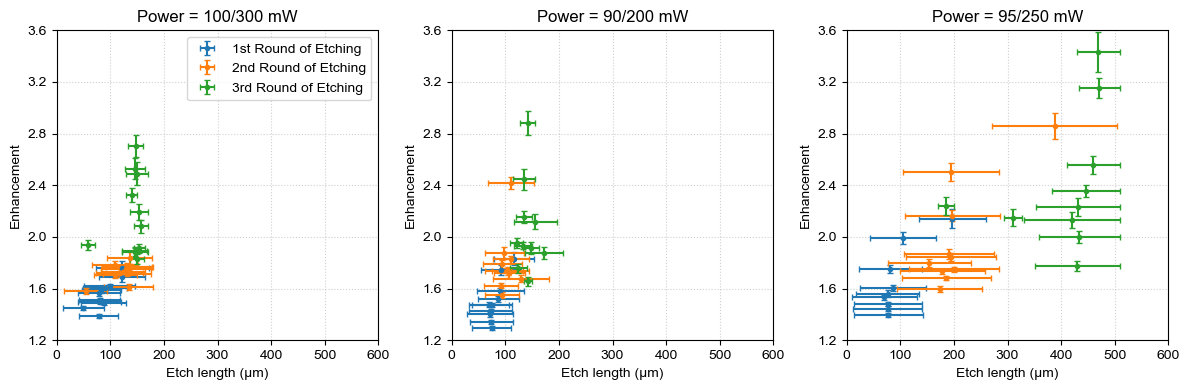

In [4]:
# For embedding fonts.
plt.rcParams['pdf.fonttype'] = 42
plt.rcParams['font.family'] = 'Arial'

# Define colors for each etch round (same order as enhancement_data and length_data).
colors = ['tab:blue', 'tab:orange', 'tab:green']  # One color per etch round.

# Get unique power groupings.
unique_powers = np.unique(parameters['power'])
# Use the same marker for all plots.
marker = '.'

# Create one subplot per unique power.
fig, axes = plt.subplots(nrows=1, ncols=len(unique_powers), figsize=(4*len(unique_powers), 4))
# In case there is only one subplot, make axes a list. (Not gonna happen!)
if len(unique_powers) == 1:
    axes = [axes]

# Loop over each unique power group.
for ax, power in zip(axes, unique_powers):
    # Get indices for patterns corresponding to the current power.
    power_indices = np.where(parameters['power'] == power)[0]
    print('Current power: ' + power + ' mW...')
    print('------------------------------------------------')
    
    # Loop over each etch round (each round gets its own color).
    for i, (enh_data, len_data) in enumerate(zip(enhancement_data, length_data)):
        # For the current etch round, extract the data for the patterns in this power group.
        # Then, sort those indices by increasing etch length.
        round_lengths = len_data['length'][power_indices]
        sort_order = np.argsort(round_lengths)
        sorted_indices = power_indices[sort_order]
        
        # Extract data using the sorted indices.
        x    = len_data['length'][sorted_indices]
        xerr = len_data['error'][sorted_indices]
        y    = enh_data['enhancement'][sorted_indices]
        yerr = enh_data['error'][sorted_indices]
        
        # Current round.
        round_label = enh_data['label']
        print('Plotting ' + round_label + '...')
        print('Pattern number:')
        print(len_data['pattern_numbers'][power_indices])
        print('~~~')
        print('Etch length (μm)')
        print(len_data['length'][power_indices])
        print('~~~')
        print('Enhancement (1):')
        print(enh_data['enhancement'][power_indices])
        print('~~~')
        print()
        
        # Plot.
        ax.errorbar(
            x, y, xerr=xerr, yerr=yerr,
            fmt=marker,
            color=colors[i],
            capsize=2,
            label=round_label
        )
    
    ax.set_xlim([0., 600.])
    ax.set_ylim([1.2, 3.6])
    ax.set_yticks(np.arange(1.2, 3.6, 0.4))
    ax.set_xlabel('Etch length (μm)')
    ax.set_ylabel('Enhancement')
    ax.set_title(f'Power = {power} mW')
    ax.grid(linestyle=':', alpha=0.6)
    ax.legend()
    print('------------------------------------------------')
    print()

# After all plotting is complete, remove legends from every subplot except the first one.
for ax in axes[1:]:
    lgnd = ax.get_legend()
    if lgnd is not None:
        lgnd.remove()

plt.tight_layout()
fig.savefig('fn_length.pdf', format='pdf')
plt.show()

### Plot enhancement as a function of period

Current power: 100/300 mW...
------------------------------------------------
Plotting 1st Round of Etching...
Pattern number:
[12 13 14 15 16 17 18 19 20 21 22]
~~~
Period (μm):
[1.5 1.5 1.5 1.5 1.5 1.5 1.4 1.3 1.2 1.1 1. ]
~~~
Enhancement (1):
[1.38704553 1.49981842 1.50943804 1.56571174 1.48538208 1.45308789
 1.58578068 1.61685105 1.60800259 1.68921319 1.76230184]
~~~

Plotting 2nd Round of Etching...
Pattern number:
[12 13 14 15 16 17 18 19 20 21 22]
~~~
Period (μm):
[1.5 1.5 1.5 1.5 1.5 1.5 1.4 1.3 1.2 1.1 1. ]
~~~
Enhancement (1):
[1.72587107 1.70648195 1.78695885 1.72309369 1.61308165 1.58309867
 1.71481982 1.75336511 1.76763005 1.76663037 1.83805459]
~~~

Plotting 3rd Round of Etching...
Pattern number:
[12 13 14 15 16 17 18 19 20 21 22]
~~~
Period (μm):
[1.5 1.5 1.5 1.5 1.5 1.5 1.4 1.3 1.2 1.1 1. ]
~~~
Enhancement (1):
[1.91277905 1.88792685 1.88241882 2.32496243 2.08249749 1.93596192
 1.83085693 2.19596183 2.49110537 2.70181188 2.52769492]
~~~

-------------------------------

meta NOT subset; don't know how to subset; dropped


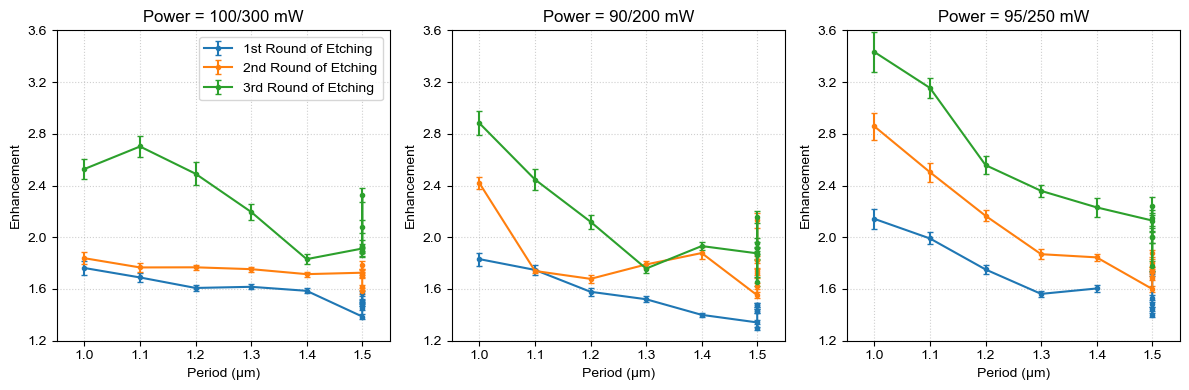

In [5]:
fig, axes = plt.subplots(nrows=1, ncols=len(unique_powers), figsize=(4*len(unique_powers), 4), sharex=True)
if len(unique_powers) == 1:
    axes = [axes]

for ax, power in zip(axes, unique_powers):
    # Get pattern indices corresponding to the current power grouping.
    power_indices = np.where(parameters['power'] == power)[0]
    print('Current power: ' + power + ' mW...')
    print('------------------------------------------------')
    
    # Retrieve the period values for these indices.
    periods = parameters['period'][power_indices]
    # Sort these indices by increasing period.
    sort_order = np.argsort(periods)
    sorted_indices = power_indices[sort_order]
    sorted_periods = parameters['period'][sorted_indices]
    
    # Loop over each etch round (each with a distinct color).
    for i, enh_data in enumerate(enhancement_data):
        # Extract enhancement data for the sorted indices.
        y    = enh_data['enhancement'][sorted_indices]
        yerr = enh_data['error'][sorted_indices]
        
        round_label = enh_data['label']
        print('Plotting ' + round_label + '...')
        print('Pattern number:')
        print(len_data['pattern_numbers'][power_indices])
        print('~~~')
        print('Period (μm):')
        print(parameters['period'][power_indices])
        print('~~~')
        print('Enhancement (1):')
        print(enh_data['enhancement'][power_indices])
        print('~~~')
        print()
        
        # Plot.
        ax.errorbar(sorted_periods, y, yerr=yerr, fmt=marker, color=colors[i],
                    linestyle='-', capsize=2, label=round_label)
    
    ax.set_xlim([0.95, 1.55])
    ax.set_xticks(np.arange(1.0, 1.55, 0.1))
    ax.set_ylim([1.2, 3.6])
    ax.set_yticks(np.arange(1.2, 3.6+0.4, 0.4))
    ax.set_xlabel('Period (μm)')
    ax.set_ylabel('Enhancement')
    ax.set_title(f'Power = {power} mW')
    ax.grid(linestyle=':', alpha=0.6)
    ax.legend()
    print('------------------------------------------------')
    print()

for ax in axes[1:]:
    lgnd = ax.get_legend()
    if lgnd is not None:
        lgnd.remove()

plt.tight_layout()
fig.savefig('fn_period.pdf', format='pdf')
plt.show()

### Plot as as function of length and period, without error bars

Current power: 100/300 mW...
------------------------------------------------
Plotting 1st Round of Etching...
Pattern number:
[12 13 14 15 16 17 18 19 20 21 22]
~~~
Period (μm):
[1.5 1.5 1.5 1.5 1.5 1.5 1.4 1.3 1.2 1.1 1. ]
~~~
Etch length (μm)
[ 78.05164319  80.1056338   80.1056338   78.63849765  87.44131455
  49.88262911  83.33333333  98.88497653  90.08215962 121.7723005
 122.0657277 ]
~~~
Enhancement (1):
[1.38704553 1.49981842 1.50943804 1.56571174 1.48538208 1.45308789
 1.58578068 1.61685105 1.60800259 1.68921319 1.76230184]
~~~

Plotting 2nd Round of Etching...
Pattern number:
[12 13 14 15 16 17 18 19 20 21 22]
~~~
Period (μm):
[1.5 1.5 1.5 1.5 1.5 1.5 1.4 1.3 1.2 1.1 1. ]
~~~
Etch length (μm)
[123.6462094  109.2057762  108.3032491  117.3285199  134.4765343
  54.15162455 130.866426   129.9638989  135.3790614  130.866426
 136.2815884 ]
~~~
Enhancement (1):
[1.72587107 1.70648195 1.78695885 1.72309369 1.61308165 1.58309867
 1.71481982 1.75336511 1.76763005 1.76663037 1.83805459]
~

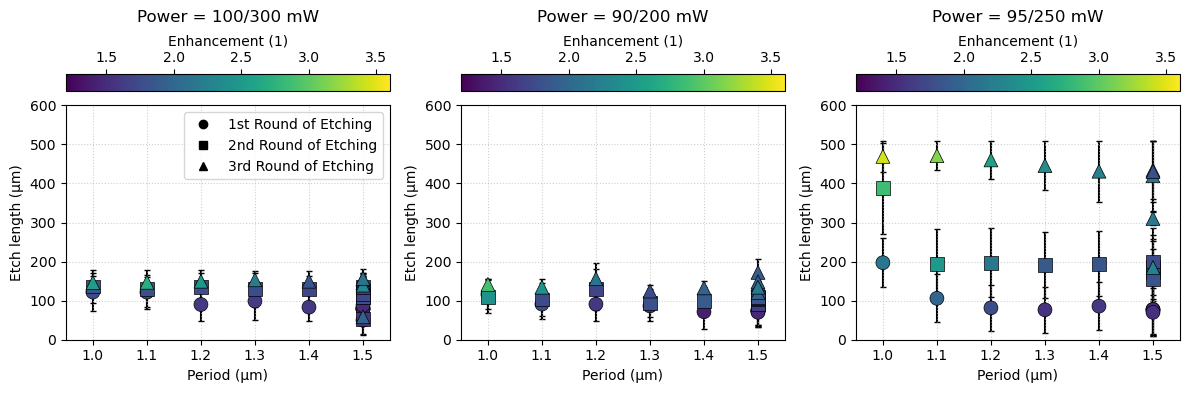

In [5]:
import matplotlib.colors as mcolors
import matplotlib.cm as cm

# Option: whether to include a thin black border around points.
include_border = True

# Define marker styles for etch rounds.
etch_markers = ['o', 's', '^']  # 1st, 2nd, 3rd rounds, respectively.
marker_size = 100

# Get unique power values from design parameters.
unique_powers = np.unique(parameters['power'])

# Set up horizontal subplots (one column per power setting).
fig, axes = plt.subplots(1, len(unique_powers), figsize=(4*len(unique_powers), 4))
if len(unique_powers) == 1:
    axes = [axes]

# Create a global colormap for enhancement. Use all enhancement values across rounds.
vmin = 1.2
vmax = 3.6
cmap = plt.cm.viridis
norm = mcolors.Normalize(vmin=vmin, vmax=vmax)
sm = cm.ScalarMappable(norm=norm, cmap=cmap)
sm.set_array([])

# Loop over each subplot corresponding to a unique power value.
for ax, power in zip(axes, unique_powers):
    # Find indices for patterns with this power.
    power_indices = np.where(parameters['power'] == power)[0]
    print('Current power: ' + power + ' mW...')
    print('------------------------------------------------')
    
    # Retrieve period values for these indices.
    x = parameters['period'][power_indices] # x because this is the x-axis variable.
    
    for i, (enh_data, len_data) in enumerate(zip(enhancement_data, length_data)):
        # Retrieve length, error, and enhancement for the current etch round.
        pattern_numbers = len_data['pattern_numbers'][power_indices] # Useful for a sanity check.
        y = len_data['length'][power_indices] # y because this is the y-axis variable.
        yerr = len_data['error'][power_indices]
        enhancement = enh_data['enhancement'][power_indices]
        
        round_label = enh_data['label']
        print('Plotting ' + round_label + '...')
        print('Pattern number:')
        print(len_data['pattern_numbers'][power_indices])
        print('~~~')
        print('Period (μm):')
        print(parameters['period'][power_indices])
        print('~~~')
        print('Etch length (μm)')
        print(len_data['length'][power_indices])
        print('~~~')
        print('Enhancement (1):')
        print(enh_data['enhancement'][power_indices])
        print('~~~')
        print()
        
        # Sort the data by period.
        sort_indices = np.argsort(x)
        sorted_pattern_numbers = pattern_numbers[sort_indices]
        x_sorted = x[sort_indices]
        y_sorted = y[sort_indices]
        yerr_sorted = yerr[sort_indices]
        enhancement_sorted = enhancement[sort_indices]
        
        # Plot error bars behind the scatter points.
        ax.errorbar(x_sorted, y_sorted, yerr=yerr_sorted, fmt='none',
                    ecolor='black', capsize=2, zorder=1)
    
        # Plot scatter points. Marker style depends on etch round.
        if include_border:
            ax.scatter(x_sorted, y_sorted, c=enhancement_sorted, cmap=cmap, norm=norm,
                       marker=etch_markers[i], s=marker_size, edgecolor='black', linewidth=0.5, zorder=2)
        else:
            ax.scatter(x_sorted, y_sorted, c=enhancement_sorted, cmap=cmap, norm=norm,
                       marker=etch_markers[i], s=marker_size, zorder=2)
    
        # Add an invisible plot for the legend entry.
        ax.plot([], [], marker=etch_markers[i], linestyle='None', color='black', label=enh_data['label'])
    
    # Colorbar.
    cbar = fig.colorbar(sm, ax=ax, orientation='horizontal', location='top')
    cbar.set_label('Enhancement (1)')
    
    ax.set_xlim([0.95, 1.55])
    ax.set_xticks(np.arange(1.0, 1.55, 0.1))
    ax.set_ylim([0., 600.])
    ax.set_xlabel('Period (μm)')
    ax.set_ylabel('Etch length (μm)')
    ax.set_title(f'Power = {power} mW', pad=60)
    ax.grid(linestyle=':', alpha=0.6)
    ax.legend()
    print('------------------------------------------------')
    print()

for ax in axes[1:]:
    lgnd = ax.get_legend()
    if lgnd is not None:
        lgnd.remove()

plt.tight_layout()
plt.show()